cd /mnt/d/typology/
docker run -p 8888:8888 -p 8787:8787 -v $(pwd):/home/gisuser/code/ -it basegis

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [2]:
print(os.getcwd())             # Shows current working directory

/home/gisuser/code


In [3]:
print(os.listdir('/home/gisuser/code/data'))     # Lists files in /data, adjust path accordingly

['3_MovingWindow', '4_TS_and_TI', '5_Typology', 'typology_TimeInterval.xlsx', 'typology_TimeSeries.xlsx']


In [5]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [4]:
#Load your data from Excel
# Replace 'your_file.xlsx' with the actual filename
# Replace 'Time_Segment' with the actual column name that contains "TS", "90-95", etc.
# orginal data: '/home/gisuser/code/code/data/typology_grapgh_data.xlsx'
df = pd.read_excel('/home/gisuser/code/data/typology_TimeInterval.xlsx', index_col=0)

# remove ts column if exists
# if 'TS_km2' in df.columns:
#     df = df.drop(columns=['TS_km2'])

# drop last column (removes 1990-2020 interval)
df = df.iloc[:, :-1]

In [5]:
print(df)
#print(df.index.tolist())

                      90-95_km2  95-00_km2  00-05_km2  05-10_km2  10-15_km2  \
Typology                                                                      
Attrition                189493     185159     152589     124886     125919   
Aggregation              115625     115794     125871     126293     120875   
Shrinkage                117412     115684     110933     102348     101371   
Perforation               45548      43513      41127      43014      46696   
Deformation                5473       5656       6070       6247       6370   
Persistent                71248      73151      76654      82193      77739   
Enlargement              162616     170288     185302     200667     196894   
Dissection               144122     137952     120639     109909     119609   
Fragmentation per se       1865       1883       2105       2249       2434   
Creation                 144525     145643     172030     199415     206303   

                      15-20_km2  
Typology         

Time Interval

KeyError: 0

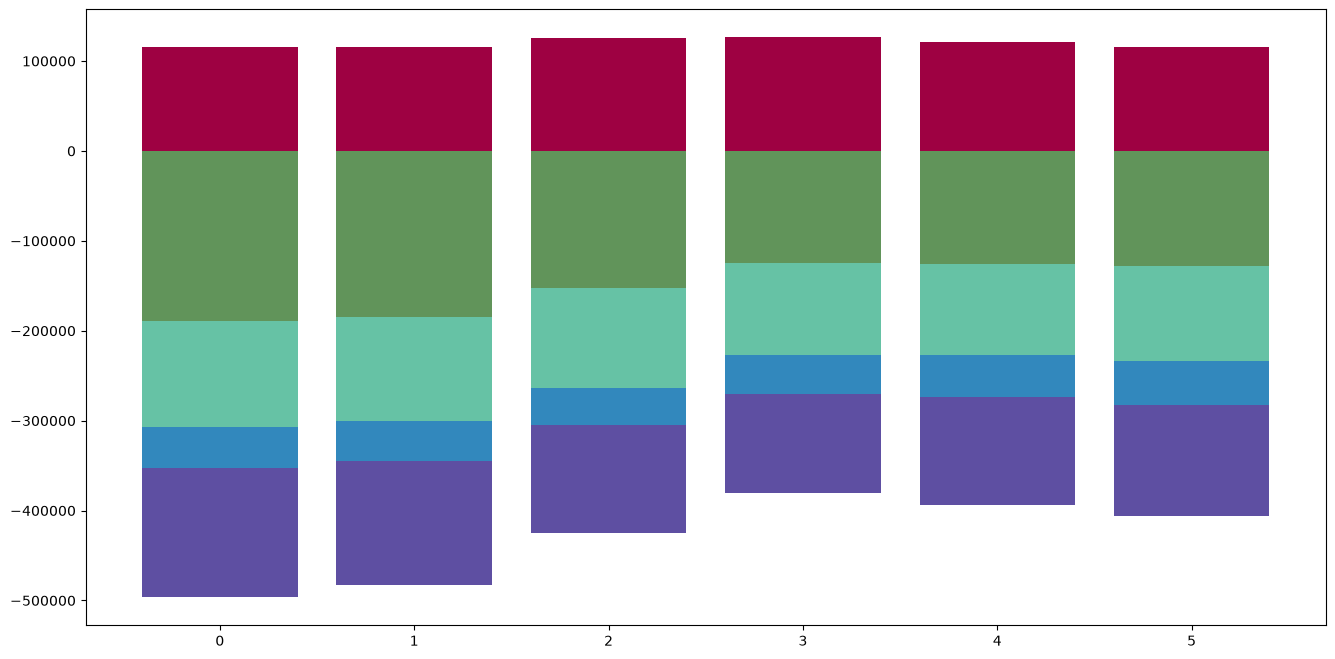

In [6]:
# TI- Version 3 - v2 + frag+deformation as one line and persistent as another line

#df = pd.read_excel('/home/gisuser/code/data/typology_TimeInterval.xlsx', index_col=0)

colors = {
    "Aggregation": "#9E0142",
    "Attrition": "#61945A", 
    "Creation": "#F46D43",
    "Dissection": "#5E4FA2",
    "Fragmentation per se": "#00A9E6",
    "Shrinkage": "#66C2A5",
    "Perforation": "#3288BD",
    "Enlargement": "#D53E4F",
    "Persistent": "#E6F598",
    "Deformation": "#FEE08B"
}

custom_x_labels = [
    "1990-1995", "1995-2000", "2000-2005",
    "2005-2010", "2010-2015", "2015-2020"
]

# Group definitions
decreasing = ["Attrition", "Shrinkage", "Perforation", "Dissection"]
increasing = ["Aggregation", "Enlargement", "Creation"]
no_change = []  # Remove Persistent from bar chart # "Deformation" (if combinging persistent and deformation in line graph)

time_points = df.columns.tolist()
fig, ax = plt.subplots(figsize=(16, 8))

# Create stacked bar chart with decreasing below 0 and increasing above 0
bottom_dec = [0] * len(time_points)
bottom_inc = [0] * len(time_points)

# Plot decreasing typologies below 0
for typ in decreasing:
    if typ in df.index:
        data = [-val for val in df.loc[typ]]  # Make negative
        ax.bar(range(len(time_points)), data, bottom=bottom_dec, color=colors.get(typ, "#cccccc"), width=0.8, label=typ)
        bottom_dec = [bottom_dec[i] + data[i] for i in range(len(data))]

# Plot increasing typologies above 0
for typ in increasing:
    if typ in df.index:
        data = df.loc[typ]
        ax.bar(range(len(time_points)), data, bottom=bottom_inc, color=colors.get(typ, "#cccccc"), width=0.8, label=typ)
        bottom_inc = [bottom_inc[i] + data[i] for i in range(len(data))]

# Plot no change typologies above increasing
for typ in no_change:
    if typ in df.index:
        data = df.loc[typ]
        ax.bar(range(len(time_points)), data, bottom=bottom_inc, color=colors.get(typ, "#cccccc"), width=0.8, label=typ)
        bottom_inc = [bottom_inc[i] + data[i] for i in range(len(data))]

# Add two separate line graphs
# Deformation + Fragmentation per se as one line graph
if "Deformation" in df.index and "Fragmentation per se" in df.index:
    combined_data = df.loc["Deformation"] + df.loc["Fragmentation per se"]
    ax.plot(range(len(time_points)), combined_data,
            color=colors["Deformation"],
            linewidth=3, 
            marker='^',
            markersize=13,
            markeredgecolor='black',
            markeredgewidth=1,
            label="Deformation + Fragmentation per se") #marker = ^ = triangle
# Persostent as another line graph 
if "Persistent" in df.index:
    #ax.plot(range(len(time_points)), df.loc["Persistent"], color=colors["Persistent"], linewidth=3, marker='o', markersize=8, label="Persistent") #marker = o = circle
    # When plotting Persistent, add markeredgecolor and markeredgewidth
    ax.plot(time_points, df.loc['Persistent'], 
            color=colors["Persistent"], 
            linewidth=3,
            marker='o',
            markersize=13,
            markeredgecolor='black',
            markeredgewidth=1, 
            label='Persistent')


# Add zero line
ax.axhline(y=0, color='black', linestyle='-', linewidth=2)

# Axis customization
#plt.rcParams['font.family'] = 'DejaVu Sans'#'cmr10'#'DejaVu Sans'
ax.margins(x=0)
# x axis
ax.set_xlabel('Time Intervals', fontsize=18, labelpad=20)
ax.set_xticklabels(custom_x_labels[:len(time_points)], weight='bold')
ax.set_xticks(range(len(time_points)))
ax.set_xticklabels(custom_x_labels[:len(time_points)])
# y axis
ax.set_ylabel('Area (km²)', fontsize=18, labelpad=20)
ax.tick_params(axis='both', which='major', labelsize=16)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '0' if x == 0 else f'{x/1000:.0f}K'))

# Legend
#ax.legend(ncol=5, bbox_to_anchor=(0.5, 1.07), loc='center', reverse=True, frameon=False, fontsize=14)
# right side legend-
#ax.legend(title='Typology', bbox_to_anchor=(1, 1), loc='upper left', reverse=True, frameon=False, fontsize=14, title_fontsize=15)
# bottom legend- upper center
ax.legend(ncol=5, bbox_to_anchor=(0.5, -0.15), loc='upper center', reverse=True, frameon=False, fontsize=17, markerscale=2, handlelength=2.2, prop={'size': 17})


# original order of legend items
#Current labels: ['Deformation + Fragmentation per se', 'Persistent', 'Attrition', 'Shrinkage', 'Perforation', 'Dissection', 'Aggregation', 'Enlargement', 'Creation']
# using :
# Get current handles and labels
# handles, labels = ax.get_legend_handles_labels()
# print("Current labels:", labels)

# # Get current handles and labels
# handles, labels = ax.get_legend_handles_labels()

# # Reorder: Creation, Dissection, Aggregation, Perforation, Enlargement, Shrinkage, Persistent, Attrition, Deformation+Fragmentation
# new_order = [8, 5, 6, 4, 7, 3, 1, 2, 0]
# ax.legend([handles[i] for i in new_order], [labels[i] for i in new_order], 
#           ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.15),
#           frameon=False, fontsize=17, markerscale=2, handlelength=2)


# Get current handles and labels
handles, labels = ax.get_legend_handles_labels()

# Reorder: Creation, Dissection, Aggregation, Perforation, Enlargement, Shrinkage, Persistent, Attrition, Deformation+Fragmentation
new_order = [8, 5, 6, 4, 7, 3, 1, 2, 0]
legend = ax.legend([handles[i] for i in new_order], [labels[i] for i in new_order], 
                   ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.15),
                   frameon=False, fontsize=17, markerscale=2, handlelength=2)

# Make Persistent and Deformation+Fragmentation markers smaller in legend only
legend.legend_handles[6].set_markersize(17)  # Persistent (index 6 in reordered list)
legend.legend_handles[8].set_markersize(17)  # Deformation+Fragmentation (index 8 in reordered list)



plt.tight_layout()
plt.show()



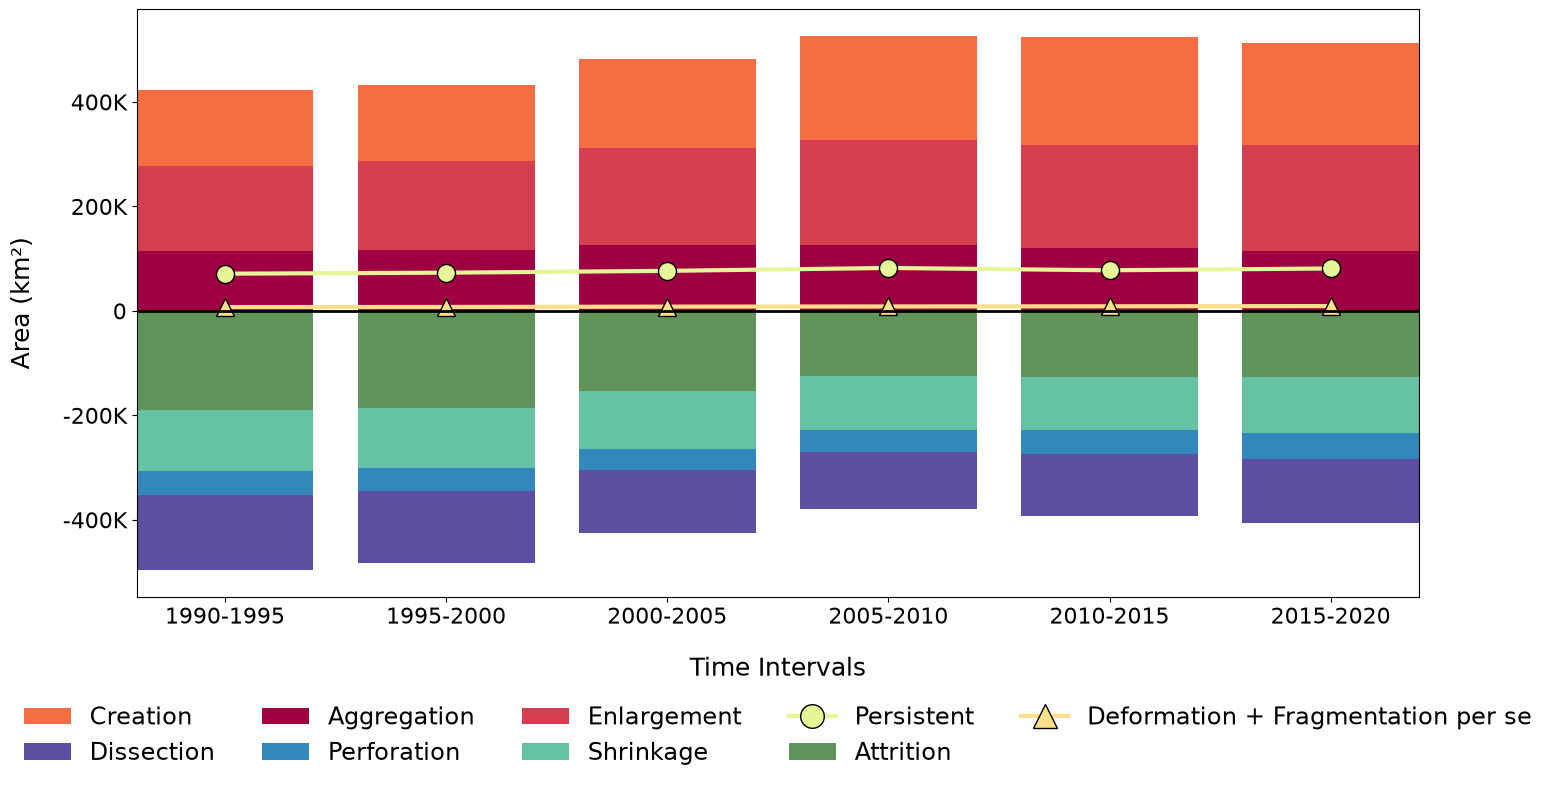

In [7]:
# updated to fix version issues
# TI- Version 3 - v2 + frag+deformation as one line and persistent as another line
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

#df = pd.read_excel('/home/gisuser/code/data/typology_TimeInterval.xlsx', index_col=0)

colors = {
    "Aggregation": "#9E0142",
    "Attrition": "#61945A",
    "Creation": "#F46D43",
    "Dissection": "#5E4FA2",
    "Fragmentation per se": "#00A9E6",
    "Shrinkage": "#66C2A5",
    "Perforation": "#3288BD",
    "Enlargement": "#D53E4F",
    "Persistent": "#E6F598",
    "Deformation": "#FEE08B"
}

custom_x_labels = [
    "1990-1995", "1995-2000", "2000-2005",
    "2005-2010", "2010-2015", "2015-2020"
]

# Group definitions
decreasing = ["Attrition", "Shrinkage", "Perforation", "Dissection"]
increasing = ["Aggregation", "Enlargement", "Creation"]
no_change = []  # Remove Persistent from bar chart

time_points = df.columns.tolist()
x = np.arange(len(time_points))
fig, ax = plt.subplots(figsize=(16, 8))

# Running bottoms for the stacked bars (numpy arrays, indexed by position)
bottom_dec = np.zeros(len(time_points))
bottom_inc = np.zeros(len(time_points))

# Plot decreasing typologies below 0
for typ in decreasing:
    if typ in df.index:
        data = -df.loc[typ].to_numpy(dtype=float)  # make negative
        ax.bar(x, data, bottom=bottom_dec, color=colors.get(typ, "#cccccc"), width=0.8, label=typ)
        bottom_dec = bottom_dec + data

# Plot increasing typologies above 0
for typ in increasing:
    if typ in df.index:
        data = df.loc[typ].to_numpy(dtype=float)
        ax.bar(x, data, bottom=bottom_inc, color=colors.get(typ, "#cccccc"), width=0.8, label=typ)
        bottom_inc = bottom_inc + data

# Plot no change typologies above increasing
for typ in no_change:
    if typ in df.index:
        data = df.loc[typ].to_numpy(dtype=float)
        ax.bar(x, data, bottom=bottom_inc, color=colors.get(typ, "#cccccc"), width=0.8, label=typ)
        bottom_inc = bottom_inc + data

# Deformation + Fragmentation per se as one line graph
if "Deformation" in df.index and "Fragmentation per se" in df.index:
    combined_data = (df.loc["Deformation"] + df.loc["Fragmentation per se"]).to_numpy(dtype=float)
    ax.plot(x, combined_data,
            color=colors["Deformation"],
            linewidth=3,
            marker='^',  # triangle
            markersize=13,
            markeredgecolor='black',
            markeredgewidth=1,
            label="Deformation + Fragmentation per se")

# Persistent as another line graph
if "Persistent" in df.index:
    ax.plot(x, df.loc["Persistent"].to_numpy(dtype=float),
            color=colors["Persistent"],
            linewidth=3,
            marker='o',  # circle
            markersize=13,
            markeredgecolor='black',
            markeredgewidth=1,
            label="Persistent")

# Add zero line
ax.axhline(y=0, color='black', linestyle='-', linewidth=2)

# Axis customization
ax.margins(x=0)
# x axis
ax.set_xlabel('Time Intervals', fontsize=18, labelpad=20)
ax.set_xticks(x)
ax.set_xticklabels(custom_x_labels[:len(time_points)])
# y axis
ax.set_ylabel('Area (km²)', fontsize=18, labelpad=20)
ax.tick_params(axis='both', which='major', labelsize=16)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, pos: '0' if v == 0 else f'{v/1000:.0f}K'))

# Legend (bottom, upper center) with custom order
# Original order: ['Deformation + Fragmentation per se', 'Persistent', 'Attrition', 'Shrinkage',
#                  'Perforation', 'Dissection', 'Aggregation', 'Enlargement', 'Creation']
handles, labels = ax.get_legend_handles_labels()

# Reorder: Creation, Dissection, Aggregation, Perforation, Enlargement, Shrinkage,
#          Persistent, Attrition, Deformation+Fragmentation
new_order = [8, 5, 6, 4, 7, 3, 1, 2, 0]
legend = ax.legend([handles[i] for i in new_order], [labels[i] for i in new_order],
                   ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.15),
                   frameon=False, fontsize=17, markerscale=2, handlelength=2)

# Make Persistent and Deformation+Fragmentation markers smaller in legend only
legend.legend_handles[6].set_markersize(17)  # Persistent
legend.legend_handles[8].set_markersize(17)  # Deformation+Fragmentation

plt.tight_layout()
plt.show()


In [8]:
# Get current handles and labels
handles, labels = ax.get_legend_handles_labels()
print("Current labels:", labels)


Current labels: ['Deformation + Fragmentation per se', 'Persistent', 'Attrition', 'Shrinkage', 'Perforation', 'Dissection', 'Aggregation', 'Enlargement', 'Creation']


In [9]:
import matplotlib.font_manager as fm
print([f.name for f in fm.fontManager.ttflist][:10])


['cmmi10', 'DejaVu Sans Display', 'DejaVu Sans', 'STIXNonUnicode', 'STIXNonUnicode', 'STIXSizeThreeSym', 'STIXGeneral', 'STIXGeneral', 'cmex10', 'STIXSizeOneSym']


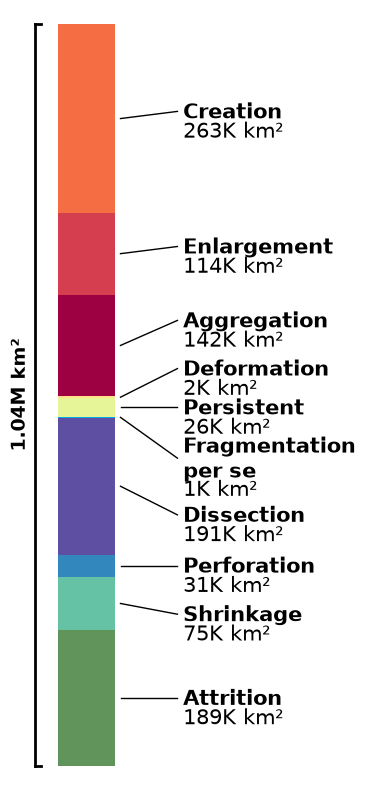

In [ ]:
# time interval

df = pd.read_excel('/home/gisuser/code/data/typology_TimeInterval.xlsx', index_col=0)
# keep only last column (removes 1990-2020 interval)
df = df.iloc[:, -1:]

# Sum all columns to get total for each typology
df_total = df.sum(axis=1)

colors = {
    "Aggregation": "#9E0142",
    "Attrition": "#61945A",
    "Creation": "#F46D43",
    "Dissection": "#5E4FA2",
    "Fragmentation per se": "#00A9E6",
    "Shrinkage": "#66C2A5",
    "Perforation": "#3288BD",
    "Enlargement": "#D53E4F",
    "Persistent": "#E6F598",
    "Deformation": "#FEE08B"
}

typology_order = [
    "Attrition", "Shrinkage", "Perforation", "Dissection", "Fragmentation per se",
    "Persistent", "Deformation",
    "Aggregation", "Enlargement", "Creation"
]

fig, ax = plt.subplots(figsize=(4, 8))

# Create single vertical bar
bottom = 0
for i, typ in enumerate(typology_order):
    if typ in df_total.index:
        value = df_total.loc[typ]
        ax.bar(0, value, bottom=bottom, color=colors.get(typ, "#cccccc"), width=0.5, label=typ)
        
        # Specific offsets for problematic labels
        mid_point = bottom + value/2
        if typ == "Deformation":
            offset = 30000#-15000 # this fixes the issue with overlap with persistent
        elif typ == "Aggregation":
            offset = 25000
        elif typ == "Persistent":
            offset = -10000
        elif typ == "Dissection":
            offset = -50000
        elif typ == "Fragmentation per se":
            offset = -67000
        elif typ == "Perforation":
            offset = -10000
        elif typ == "Shrinkage":
            offset = -25000
        elif typ == "Attrition":
            offset = -10000
        else:
            offset = 0
        
        label_y = mid_point + offset
        
        # Add diagonal leader line- original line
        #ax.plot([0.3, 0.8], [mid_point, label_y], 'k-', linewidth=1)
        # Add leader line pointing to upper part of text
        ax.plot([0.3, 0.8], [mid_point, label_y + 10000], 'k-', linewidth=1)
        
        # Shorten long names for better display
        #display_name = "Fragmentation" if typ == "Fragmentation per se" else typ
        # both typology and area are not bold
        #ax.text(0.85, label_y, f'{display_name}\n{value/1000:.0f}K km²', va='center', ha='left', fontsize=10)
        # typology bold, area not bold
        #ax.text(0.85, label_y, f'$\\bf{{{typ}}}$\n{value/1000:.0f}K km²', va='center', ha='left', fontsize=10)

        
        # original - both typology and area bold
        # display_name = typ.replace("Fragmentation per se", "Fragmentation\nper se")
        # ax.text(0.85, label_y, f'{display_name}\n{value/1000:.0f}K km²', va='center', ha='left', fontsize=15, weight='bold')
        
        # display_name = typ.replace("Fragmentation per se", "Fragmentation\nper se")
        # # Bold typology name
        # ax.text(0.85, label_y + 8000, display_name, va='center', ha='left', fontsize=15, weight='bold')
        # # Normal area value
        # ax.text(0.85, label_y - 15000, f'{value/1000:.0f}K km²', va='center', ha='left', fontsize=15, weight='normal')

        display_name = typ.replace("Fragmentation per se", "Fragmentation\nper se")
        # Bold typology name
        ax.text(0.85, label_y + 8000, display_name, va='center', ha='left', fontsize=15, weight='bold')
        # Normal area value with specific offset for Fragmentation per se
        number_offset = -35000 if typ == "Fragmentation per se" else -19000
        ax.text(0.85, label_y + number_offset, f'{value/1000:.0f}K km²', va='center', ha='left', fontsize=15, weight='normal')


        
        bottom += value # stacks bars

# orignal code from amazon q with stnadard graph layout
#ax.set_xlim(-0.5, 2.5)
#ax.set_ylabel('Total Area (km²)', fontsize=12)
#ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1000:.0f}K'))
#ax.set_xticks([])
#ax.set_xlabel('1990-2020 Time Series', fontsize=12)

# Customized graph layout
df_total = df.sum(axis=1)
total_sum = df_total.sum()

ax.set_yticks([]) # removes tick marks on both axes
ax.plot([-0.45, -0.45], [0, total_sum], 'k-', linewidth=2)  # Vertical bracket line
ax.plot([-0.45, -0.4], [0, 0], 'k-', linewidth=2)  # Bottom bracket
ax.plot([-0.45, -0.4], [total_sum, total_sum], 'k-', linewidth=2)  # Top bracket

# added to fix bracket label to show million
total_label = f'{total_sum/1e6:.2f}M km²' if total_sum >= 1e6 else f'{total_sum/1e3:.0f}K km²'
ax.text(-0.5, total_sum/2, total_label, rotation=90, va='center', ha='right', fontsize=14, weight="bold")
#ax.text(-0.5, total_sum/2, f'{total_sum/1000:.0f}K km²', rotation=90, va='center', ha='right', fontsize=14, weight="bold") # bracket label # orig sise 12

ax.xaxis.set_visible(False) # remove x axis line
ax.set_ylim(-20000, total_sum + 20000) # adds space bewlow x to prevent cutting off bottom brack (bc using the above line)
ax.set_xlim(-0.6, 2.5)

# remove box around graph
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)


plt.tight_layout()
plt.show()

Time Series

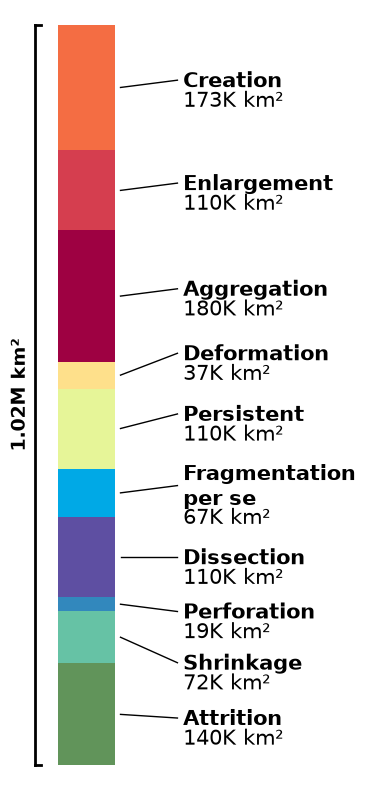

In [16]:
# time series 
df = pd.read_excel('/home/gisuser/code/data/typology_TimeSeries.xlsx', index_col=0)
# Sum all columns to get total for each typology
df_total = df.sum(axis=1)

colors = {
    "Aggregation": "#9E0142",
    "Attrition": "#61945A",
    "Creation": "#F46D43",
    "Dissection": "#5E4FA2",
    "Fragmentation per se": "#00A9E6",
    "Shrinkage": "#66C2A5",
    "Perforation": "#3288BD",
    "Enlargement": "#D53E4F",
    "Persistent": "#E6F598",
    "Deformation": "#FEE08B"
}

typology_order = [
    "Attrition", "Shrinkage", "Perforation", "Dissection", "Fragmentation per se",
    "Persistent", "Deformation",
    "Aggregation", "Enlargement", "Creation"
]

fig, ax = plt.subplots(figsize=(4, 8))

# Create single vertical bar
bottom = 0
for i, typ in enumerate(typology_order):
    if typ in df_total.index:
        value = df_total.loc[typ]
        ax.bar(0, value, bottom=bottom, color=colors.get(typ, "#cccccc"), width=0.5, label=typ)
        
        # Specific offsets for problematic labels
        mid_point = bottom + value/2
        if typ == "Deformation":
            offset = 20000#-15000 # this fixes the issue with overlap with persistent
        elif typ == "Persistent":
            offset = 10000
        elif typ == "Dissection":
            offset = -10000
        elif i in [3]: #[2, 3]:  # Perforation, Fragmentation, Dissection
            offset = 20000 # fixes overlap issue for these typologies 
        elif typ == "Perforation":
            offset = -20000
        elif typ == "Shrinkage":
            offset = -45000
        elif typ == "Attrition":
            offset = -15000
        else:
            offset = 0
        
        label_y = mid_point + offset
        
        # Add diagonal leader line- original line
        #ax.plot([0.3, 0.8], [mid_point, label_y], 'k-', linewidth=1)
        # Add leader line pointing to upper part of text
        ax.plot([0.3, 0.8], [mid_point, label_y + 10000], 'k-', linewidth=1)
        
        # Shorten long names for better display
        #display_name = "Fragmentation" if typ == "Fragmentation per se" else typ
        # both typology and area are not bold
        #ax.text(0.85, label_y, f'{display_name}\n{value/1000:.0f}K km²', va='center', ha='left', fontsize=10)
        # typology bold, area not bold
        #ax.text(0.85, label_y, f'$\\bf{{{typ}}}$\n{value/1000:.0f}K km²', va='center', ha='left', fontsize=10)

        
        # original - both typology and area bold
        # display_name = typ.replace("Fragmentation per se", "Fragmentation\nper se")
        # ax.text(0.85, label_y, f'{display_name}\n{value/1000:.0f}K km²', va='center', ha='left', fontsize=15, weight='bold')
        
        # display_name = typ.replace("Fragmentation per se", "Fragmentation\nper se")
        # # Bold typology name
        # ax.text(0.85, label_y + 8000, display_name, va='center', ha='left', fontsize=15, weight='bold')
        # # Normal area value
        # ax.text(0.85, label_y - 15000, f'{value/1000:.0f}K km²', va='center', ha='left', fontsize=15, weight='normal')

        display_name = typ.replace("Fragmentation per se", "Fragmentation\nper se")
        # Bold typology name
        ax.text(0.85, label_y + 8000, display_name, va='center', ha='left', fontsize=15, weight='bold')
        # Normal area value with specific offset for Fragmentation per se
        number_offset = -35000 if typ == "Fragmentation per se" else -19000
        ax.text(0.85, label_y + number_offset, f'{value/1000:.0f}K km²', va='center', ha='left', fontsize=15, weight='normal')


        
        bottom += value # stacks bars

# orignal code from amazon q with stnadard graph layout
#ax.set_xlim(-0.5, 2.5)
#ax.set_ylabel('Total Area (km²)', fontsize=12)
#ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1000:.0f}K'))
#ax.set_xticks([])
#ax.set_xlabel('1990-2020 Time Series', fontsize=12)

# Customized graph layout
df_total = df.sum(axis=1)
total_sum = df_total.sum()

ax.set_yticks([]) # removes tick marks on both axes
ax.plot([-0.45, -0.45], [0, total_sum], 'k-', linewidth=2)  # Vertical bracket line
ax.plot([-0.45, -0.4], [0, 0], 'k-', linewidth=2)  # Bottom bracket
ax.plot([-0.45, -0.4], [total_sum, total_sum], 'k-', linewidth=2)  # Top bracket

# added to fix bracket label to show million
total_label = f'{total_sum/1e6:.2f}M km²' if total_sum >= 1e6 else f'{total_sum/1e3:.0f}K km²'
ax.text(-0.5, total_sum/2, total_label, rotation=90, va='center', ha='right', fontsize=14, weight="bold")
#ax.text(-0.5, total_sum/2, f'{total_sum/1000:.0f}K km²', rotation=90, va='center', ha='right', fontsize=14, weight="bold") # bracket label # orig sise 12

ax.xaxis.set_visible(False) # remove x axis line
ax.set_ylim(-20000, total_sum + 20000) # adds space bewlow x to prevent cutting off bottom brack (bc using the above line)
ax.set_xlim(-0.6, 2.5)

# remove box around graph
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)


plt.tight_layout()
plt.show()


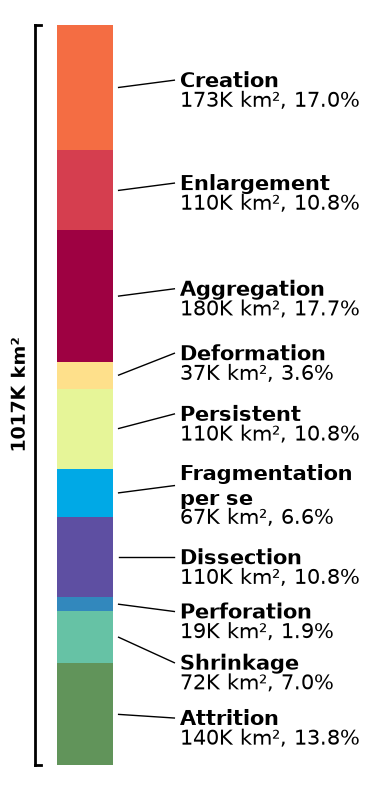

In [17]:
# Time series + area + percent cover 
df = pd.read_excel('/home/gisuser/code/data/typology_TimeSeries.xlsx', index_col=0)
# Sum all columns to get total for each typology
df_total = df.sum(axis=1)

# Calculate total area for percent cover calculation
total_sum = df_total.sum()

colors = {
    "Aggregation": "#9E0142",
    "Attrition": "#61945A",
    "Creation": "#F46D43",
    "Dissection": "#5E4FA2",
    "Fragmentation per se": "#00A9E6",
    "Shrinkage": "#66C2A5",
    "Perforation": "#3288BD",
    "Enlargement": "#D53E4F",
    "Persistent": "#E6F598",
    "Deformation": "#FEE08B"
}

typology_order = [
    "Attrition", "Shrinkage", "Perforation", "Dissection", "Fragmentation per se",
    "Persistent", "Deformation",
    "Aggregation", "Enlargement", "Creation"
]

fig, ax = plt.subplots(figsize=(4, 8))

# Create single vertical bar
bottom = 0
for i, typ in enumerate(typology_order):
    if typ in df_total.index:
        value = df_total.loc[typ]
        
        ax.bar(0, value, bottom=bottom, color=colors.get(typ, "#cccccc"), width=0.5, label=typ)
        
        # Specific offsets for problematic labels
        mid_point = bottom + value/2
        if typ == "Deformation":
            offset = 20000
        elif typ == "Persistent":
            offset = 10000
        elif typ == "Dissection":
            offset = -10000
        elif i in [3]:
            offset = 20000
        elif typ == "Perforation":
            offset = -20000
        elif typ == "Shrinkage":
            offset = -45000
        elif typ == "Attrition":
            offset = -15000
        else:
            offset = 0
        
        label_y = mid_point + offset
        
        # Add leader line pointing to upper part of text
        ax.plot([0.3, 0.8], [mid_point, label_y + 10000], 'k-', linewidth=1)
        
        display_name = typ.replace("Fragmentation per se", "Fragmentation\nper se")
        
        # Format area with commas and calculate P_cover
        area_km2 = value / 1000
        area_str = f"{area_km2:,.0f}K km²"
        p_cover = (value / total_sum) * 100
        p_cover_str = f"{p_cover:.1f}%"
        
        # Bold typology name
        ax.text(0.85, label_y + 8000, display_name, va='center', ha='left', fontsize=15, weight='bold')
        # Area and P_cover on one line with comma separator
        number_offset = -35000 if typ == "Fragmentation per se" else -19000
        ax.text(0.85, label_y + number_offset, f"{area_str}, {p_cover_str}", 
                va='center', ha='left', fontsize=15, weight='normal')

        bottom += value  # stacks bars

# Customized graph layout
ax.set_yticks([])  # removes tick marks on both axes
ax.plot([-0.45, -0.45], [0, total_sum], 'k-', linewidth=2)  # Vertical bracket line
ax.plot([-0.45, -0.4], [0, 0], 'k-', linewidth=2)  # Bottom bracket
ax.plot([-0.45, -0.4], [total_sum, total_sum], 'k-', linewidth=2)  # Top bracket
ax.text(-0.5, total_sum/2, f'{total_sum/1000:.0f}K km²', rotation=90, va='center', ha='right', fontsize=14, weight="bold")
ax.xaxis.set_visible(False)  # remove x axis line
ax.set_ylim(-20000, total_sum + 20000)
ax.set_xlim(-0.6, 2.5)

# remove box around graph
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.show()
